# Differentialgleichungen I: Grundlagen, Trennung der Variablen und Ähnlichkeits-DGL

**Begleit-Notebook zum Vorlesungsskript „Angewandte Mathematik – 1. Gewöhnliche Differentialgleichungen“, Teil 1 (Abschnitte 1.1 bis 1.4)**

Das Notebook folgt der Gliederung des Skripts. Definitionen, Sätze und Beispiele tragen dieselbe Nummer wie im Skript. Zu jedem Beispiel gibt es

* den Rechenweg aus dem Skript in Formeln,
* eine **Probe mit SymPy**: Die Lösung wird in die DGL eingesetzt, das Residuum muss 0 sein,
* eine **Grafik** und an einigen Stellen ein **interaktives Element** (Schieberegler).

**Voraussetzungen:** `numpy`, `sympy`, `matplotlib`, `ipywidgets`
**Arbeitsweise:** Zellen der Reihe nach ausführen und die Kontrollausgaben prüfen.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/differentialgleichungen/01_dgl_variablentrennung_aehnlichkeitsdgl.ipynb)

**Inhalt**

0. Hinweise für das gesamte Kapitel (Integrationskonstanten, Logarithmenregeln)
1. Abschnitt 1.1: Motivation – Newtons Abkühlungsgesetz (Beispiel 1.1.1)
2. Abschnitt 1.2: Allgemeine Definition einer DGL (Definition 1.2.1, Beispiele 1.2.2 bis 1.2.6)
3. Abschnitt 1.3: DGL der Form $y' = f(y)\cdot g(x)$ – Trennung der Variablen (Satz 1.3.1, Beispiele 1.3.2 bis 1.3.6, Lösungsmethode 1.3.7)
4. Abschnitt 1.4: Ähnlichkeitsdifferentialgleichungen $y' = f(y/x)$ (Satz 1.4.1, Beispiele 1.4.2 bis 1.4.6, Lösungsmethode 1.4.4)
5. Ausblick: Numerische Lösung mit dem Euler-Verfahren (Kapitel 4)

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
plt.style.use('default')
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})
sp.init_printing()

x, t = sp.symbols('x t', real=True)
lam = sp.symbols('lambda')


def pruefe(name, residuum):
    """Vereinfacht ein Residuum, gibt es aus und bricht ab, falls es nicht 0 ist."""
    r = sp.simplify(residuum)
    if isinstance(r, sp.MatrixBase):
        ok = all(sp.simplify(e) == 0 for e in r)
    else:
        ok = r == 0
    print(f'Probe {name}: Residuum = {r}  ->', 'ok' if ok else 'FEHLER')
    assert ok

**Hilfsfunktion:** `richtungsfeld(F, xbereich, ybereich)` zeichnet das Richtungsfeld der DGL $y' = F(x,y)$: In jedem Gitterpunkt einen kurzen Strich mit der vorgeschriebenen Steigung. Sie wird im ganzen Notebook verwendet.

In [2]:
def richtungsfeld(F, xbereich, ybereich, n=21, ax=None, farbe='#9bb7d4'):
    """Zeichnet das Richtungsfeld der DGL y' = F(x, y) mit gleich langen Strichen."""
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    V = F(X, Y)
    # Striche in Bildschirmkoordinaten gleich lang machen
    sx = (xbereich[1] - xbereich[0]); sy = (ybereich[1] - ybereich[0])
    L = np.hypot(1/sx, V/sy)
    ax.quiver(X, Y, 1/L, V/L, color=farbe, pivot='mid', angles='xy',
              headwidth=0, headlength=0, headaxislength=0, width=0.003)
    ax.set_xlim(*xbereich); ax.set_ylim(*ybereich)

## 0. Hinweise für das gesamte Kapitel

1. Jede Integration liefert eine neue Konstante. Alle diese Konstanten (und additive konstante Terme) werden am Ende zu **einer** Konstanten $C$ zusammengefasst und auf die rechte Seite geschrieben.
2. Sehr häufig entstehen Ausdrücke wie $\ln|x|$ oder $\ln(x^2+1)$. Dann lohnt es sich, die Konstante von Anfang an in der Form $\ln|C|$ anzusetzen statt als $C$: Beide Seiten lassen sich mit den Logarithmengesetzen zu je einem Logarithmus zusammenfassen, und die Gleichung ist in einem Schritt nach $y$ auflösbar.
3. Dazu benötigen wir die folgenden Regeln, die ab hier ohne weiteren Verweis verwendet werden:

| Regel | Aussage |
|---|---|
| R1 | $\ln a + \ln b = \ln(a\cdot b)$ |
| R2 | $\ln a - \ln b = \ln(a/b)$ |
| R3 | $n\cdot\ln a = \ln a^n$ |
| R4 | $e^{\ln a} = a$, $\quad \ln e^n = n$ |
| R5 | Entlogarithmieren: $\ln a = b \Rightarrow a = e^b$, $\quad \ln a = \ln b \Rightarrow a = b$ |
| R6 | $\lvert x\rvert = a > 0 \Rightarrow x = \pm a$, $\quad \lvert x\rvert = \lvert a\rvert \Rightarrow x = \pm a$ |
| R7 | $a^m\cdot a^n = a^{m+n}$, $\quad a^m\cdot a^{-m} = a^0 = 1$ |

Die logarithmische Form der Konstanten und das Auflösen nach $y$ über R5 begegnen Ihnen bei fast jeder Trennung der Variablen. Die Fallunterscheidung aus R6 entscheidet dort über das Vorzeichen der Lösung.

**Beispiel zu (2):** $y' = y/x$ liefert nach Trennung der Variablen $\dfrac{dy}{y} = \dfrac{dx}{x}$.

* Ansatz $\ln|C|$: $\ln|y| = \ln|x| + \ln|C| = \ln|C\cdot x| \;\Rightarrow\; y = C\cdot x$
* Ansatz $C$: $\ln|y| = \ln|x| + C \;\Rightarrow\; y = e^C\cdot|x|$ – der Faktor $e^C$ muss erst wieder zu einer neuen Konstanten zusammengefasst werden.

Die folgende Zelle prüft die Regeln R1 bis R3 für positive Zahlen und bestätigt das Ergebnis $y = Cx$.

In [3]:
a, b, n = sp.symbols('a b n', positive=True)
print('R1:', sp.simplify(sp.expand_log(sp.log(a*b)) - (sp.log(a) + sp.log(b))) == 0)
print('R2:', sp.simplify(sp.expand_log(sp.log(a/b)) - (sp.log(a) - sp.log(b))) == 0)
print('R3:', sp.simplify(sp.expand_log(sp.log(a**n), force=True) - n*sp.log(a)) == 0)

C = sp.symbols('C')
y_bsp = C*x
pruefe("y = Cx in y' = y/x", sp.diff(y_bsp, x) - y_bsp/x)

R1: True
R2: True
R3: True
Probe y = Cx in y' = y/x: Residuum = 0  -> ok


## 1. Abschnitt 1.1: Motivation

**Differentialgleichungen** sind Gleichungen, die neben einer Funktion auch Ableitungen dieser Funktion enthalten. Sie liefern den Zusammenhang zwischen der Steigung oder Krümmung einer Funktion und der Funktion selbst. Solche Zusammenhänge lassen sich bei dynamischen Vorgängen oft durch Messungen ermitteln; die Lösung der DGL liefert daraus die Funktion, die den Vorgang beschreibt.

| gewöhnliche DGL (ODE) | partielle DGL (PDE) |
|---|---|
| $\dfrac{dy}{dx} = -x$ | $\dfrac{\partial u(x,y)}{\partial x} - x\,\dfrac{\partial u(x,y)}{\partial y} = 0$ |
| gesuchte Funktion hängt von **einer** Variablen ab | gesuchte Funktion hängt von **mehreren** Variablen ab (nicht Gegenstand der Vorlesung) |

### Beispiel 1.1.1: Der Kaffee auf dem Schreibtisch

Eine Mitarbeiterin stellt um 9:00 Uhr einen frischen Kaffee mit $85\,^\circ\mathrm{C}$ auf ihren Schreibtisch. Die Raumtemperatur beträgt konstant $22\,^\circ\mathrm{C}$. Um 9:10 Uhr misst sie $71\,^\circ\mathrm{C}$.

**Fragen:** Wie viele Minuten hätte sie warten müssen, bis der Kaffee trinkfertige $60\,^\circ\mathrm{C}$ hat? Wann hat er nur noch $30\,^\circ\mathrm{C}$?

**Modellierung (Newtons Abkühlungsgesetz):**
$$\frac{dT}{dt} = -k\,\bigl(T(t) - U\bigr)$$

* $t \ge 0$: Zeit in Minuten ab 9:00 Uhr
* $T(t)$: Temperatur des Kaffees in $^\circ\mathrm{C}$
* $U = 22\,^\circ\mathrm{C}$: konstante Umgebungstemperatur
* $k > 0$: Abkühlungskoeffizient in $\mathrm{min}^{-1}$

**Bedingungen:** $T(0) = 85$ (Anfangsbedingung), $T(10) = 71$ (Messung).
**Gesucht:** $T(t)$, der Parameter $k$, sowie die Zeitpunkte mit $T(t) = 60$ und $T(t) = 30$.

Die DGL sagt: Die Abkühlgeschwindigkeit ist proportional zur Temperaturdifferenz. Ist der Kaffee viel wärmer als der Raum, kühlt er schnell ab, nahe der Raumtemperatur nur noch langsam. Die Lösung folgt in **Beispiel 1.3.6** mit der Trennung der Variablen. Vorab zeigt die Grafik nur, was wir wissen: zwei Messpunkte und die Steigungsvorgabe der DGL.

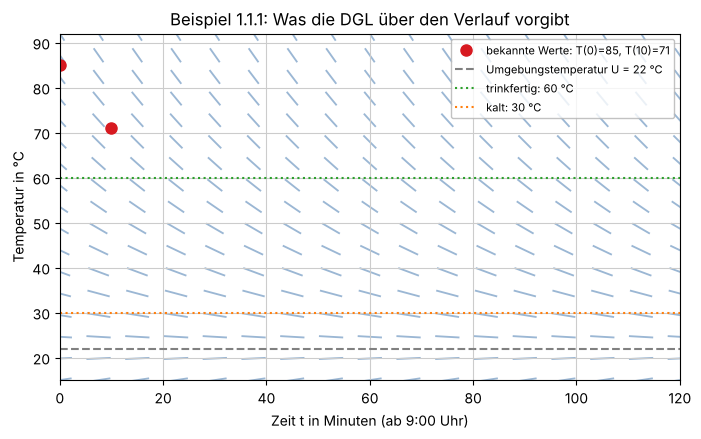

In [4]:
U_kaffee = 22
k_schaetz = 0.025                      # nur zur Illustration; k wird in Beispiel 1.3.6 berechnet
richtungsfeld(lambda tt, TT: -k_schaetz*(TT - U_kaffee), (0, 120), (15, 92), n=17)
plt.plot([0, 10], [85, 71], 'o', color='#d71920', markersize=8, label='bekannte Werte: T(0)=85, T(10)=71')
plt.axhline(U_kaffee, color='gray', linestyle='--', label='Umgebungstemperatur U = 22 °C')
plt.axhline(60, color='C2', linestyle=':', label='trinkfertig: 60 °C')
plt.axhline(30, color='C1', linestyle=':', label='kalt: 30 °C')
plt.xlabel('Zeit t in Minuten (ab 9:00 Uhr)'); plt.ylabel('Temperatur in °C')
plt.title('Beispiel 1.1.1: Was die DGL über den Verlauf vorgibt')
plt.legend(loc='upper right', fontsize=8); plt.show()

## 2. Abschnitt 1.2: Allgemeine Definition einer Differentialgleichung

### Definition 1.2.1 (Differentialgleichung)

Ist $F$ eine Funktion, so heißt eine Gleichung der Form
$$F\bigl(x, y, y', y'', \dots, y^{(n)}\bigr) = 0 \tag{1.1}$$
eine **gewöhnliche Differentialgleichung in impliziter Form** (Beispiel: $y' - x^2 - y = 0$) und
$$y^{(n)} = F\bigl(x, y, y', \dots, y^{(n-1)}\bigr)$$
eine **gewöhnliche Differentialgleichung in expliziter Form** (Beispiel: $y' = x^2 + y$).

* Eine Funktion $y = y(x)$, die auf einem nichtleeren Intervall $I \subset \mathbb{R}$ definiert ist und (1.1) erfüllt, heißt **Lösung** der DGL.
* Die Zahl $n$ heißt **Ordnung** der DGL.
* Die DGL heißt **linear**, falls Funktionen $p_i(x)$, $r(x)$ existieren, so dass sie die Form
$$p_n(x)\,y^{(n)} + p_{n-1}(x)\,y^{(n-1)} + \dots + p_1(x)\,y' + p_0(x)\,y = r(x)$$
hat. Andernfalls heißt sie **nichtlinear**.

Meist sucht man eine Lösung, die an einer Stelle $x_0$ vorgegebene **Anfangswerte** $y(x_0) = y_0,\; y'(x_0) = y_0',\; \dots,\; y^{(n-1)}(x_0) = y_0^{(n-1)}$ erfüllt.

* **Anfangswertproblem (AWP):** Alle Bedingungen an **einer** Stelle $x_0$. Typisch bei zeitabhängigen Prozessen (Fallbewegung, Erwärmung, elektrische Schaltkreise).
* **Randwertproblem (RWP):** Bedingungen an **verschiedenen** Stellen des Intervalls. Typisch bei stationären oder räumlichen Problemen (Temperaturverteilung in einem Stab mit festen Endtemperaturen).

**Bemerkung:** Eine lineare DGL hat folgende Eigenschaften:

* $y$ und seine Ableitungen $y', y'', \dots, y^{(n)}$ treten nur in der ersten Potenz auf.
* Es gibt keine nichtlinearen Terme wie $y^2$, $\sqrt{y}$, $(y')^2$, $e^y$, $\sin y$, $\cos y'$.
* Es gibt keine gemischten Produkte wie $y\,y'$, $y\,y''$, $y'\,y''$.

Die Koeffizienten $p_i(x)$ dürfen dagegen beliebige Funktionen von $x$ sein, z. B. $\sin x$ oder $e^x$.

### Beispiele 1.2.2 und 1.2.3: Ordnung und Linearität bestimmen

Die Bemerkung oben lässt sich direkt in ein kleines Prüfprogramm übersetzen: Wir ersetzen $y, y', y'', \dots$ durch Platzhalter $Y_0, Y_1, Y_2, \dots$. Die DGL ist genau dann linear, wenn der entstehende Ausdruck ein **Polynom vom Gesamtgrad höchstens 1** in diesen Platzhaltern ist. Terme wie $\ln Y_0$ oder $e^{Y_0}$ sind gar kein Polynom, $Y_1^2$ oder $Y_0Y_1$ haben Grad 2. Die Ordnung liefert `sp.ode_order`.

In [5]:
def klassifiziere(ausdruck, f, var):
    # Ordnung und Linearität einer DGL der Form ausdruck = 0 für die Funktion f(var)
    n = sp.ode_order(ausdruck, f(var))
    Y = sp.symbols(f'Y0:{n+1}')
    e = ausdruck
    for k in range(n, 0, -1):                      # höchste Ableitung zuerst ersetzen
        e = e.subs(f(var).diff(var, k), Y[k])
    e = e.subs(f(var), Y[0])
    try:
        linear = sp.Poly(e, *Y).total_degree() <= 1
    except sp.PolynomialError:                     # z. B. ln(Y0), exp(Y0)
        linear = False
    return n, linear


y = sp.Function('y'); s = sp.Function('s'); h = sp.Function('h'); nf = sp.Function('n')
k, EI, Nk, m, g, c, q = sp.symbols('k EI N m g c q', positive=True)

beispiele_122 = [
    ("y' + 2xy + 1 = 0",            y(x).diff(x) + 2*x*y(x) + 1,                     y, x),
    ("2y' + sin x = 0",             2*y(x).diff(x) + sp.sin(x),                      y, x),
    ("n' = -k n",                   nf(t).diff(t) + k*nf(t),                         nf, t),
    ("h' = -k sqrt(h)",             h(t).diff(t) + k*sp.sqrt(h(t)),                  h, t),
    ("EI y'' + N y = 0",            EI*y(x).diff(x, 2) + Nk*y(x),                    y, x),
    ("m s'' = m g",                 m*s(t).diff(t, 2) - m*g,                         s, t),
    ("m s'' + c s' = m g",          m*s(t).diff(t, 2) + c*s(t).diff(t) - m*g,        s, t),
    ("y'' + y' - xy = x",           y(x).diff(x, 2) + y(x).diff(x) - x*y(x) - x,     y, x),
    ("y''' + y'' + y'y - 2x + 4 = 0", y(x).diff(x, 3) + y(x).diff(x, 2) + y(x).diff(x)*y(x) - 2*x + 4, y, x),
    ("x y''' + 2e^x y'' + y = 2x^2", x*y(x).diff(x, 3) + 2*sp.exp(x)*y(x).diff(x, 2) + y(x) - 2*x**2, y, x),
    ("y'''' = q",                   y(x).diff(x, 4) - q,                             y, x),
]
beispiele_123 = [
    ("y' + 3x + 5 = 0",             y(x).diff(x) + 3*x + 5),
    ("4y''' + (sin x) y'' - 3xy = 4x", 4*y(x).diff(x, 3) + sp.sin(x)*y(x).diff(x, 2) - 3*x*y(x) - 4*x),
    ("y''' - 2x^4 y'' + x^2 y' - (cos x) y = sin^2 x - 5x",
     y(x).diff(x, 3) - 2*x**4*y(x).diff(x, 2) + x**2*y(x).diff(x) - sp.cos(x)*y(x) - sp.sin(x)**2 + 5*x),
    ("(y')^2 - 2y = 3",             y(x).diff(x)**2 - 2*y(x) - 3),
    ("y'' + y'y = 0",               y(x).diff(x, 2) + y(x).diff(x)*y(x)),
    ("y'' + y' - y^2 = 0",          y(x).diff(x, 2) + y(x).diff(x) - y(x)**2),
    ("y'' + y' - xy = x",           y(x).diff(x, 2) + y(x).diff(x) - x*y(x) - x),
    ("y' + ln y = 2x - 3",          y(x).diff(x) + sp.log(y(x)) - 2*x + 3),
    ("y'' + 2y' + e^y = 0",         y(x).diff(x, 2) + 2*y(x).diff(x) + sp.exp(y(x))),
]

print('Beispiel 1.2.2: Ordnung')
for text, ausdruck, f, var in beispiele_122:
    n, _ = klassifiziere(ausdruck, f, var)
    print(f'  {text:34s} gesucht: {f.__name__}({var}),  Ordnung {n}')

print('\nBeispiel 1.2.3: Linearität und Ordnung')
for text, ausdruck in beispiele_123:
    n, linear = klassifiziere(ausdruck, y, x)
    print(f'  {text:55s} {"linear" if linear else "nichtlinear":12s} Ordnung {n}')

Beispiel 1.2.2: Ordnung
  y' + 2xy + 1 = 0                   gesucht: y(x),  Ordnung 1
  2y' + sin x = 0                    gesucht: y(x),  Ordnung 1
  n' = -k n                          gesucht: n(t),  Ordnung 1
  h' = -k sqrt(h)                    gesucht: h(t),  Ordnung 1
  EI y'' + N y = 0                   gesucht: y(x),  Ordnung 2
  m s'' = m g                        gesucht: s(t),  Ordnung 2
  m s'' + c s' = m g                 gesucht: s(t),  Ordnung 2
  y'' + y' - xy = x                  gesucht: y(x),  Ordnung 2
  y''' + y'' + y'y - 2x + 4 = 0      gesucht: y(x),  Ordnung 3
  x y''' + 2e^x y'' + y = 2x^2       gesucht: y(x),  Ordnung 3
  y'''' = q                          gesucht: y(x),  Ordnung 4

Beispiel 1.2.3: Linearität und Ordnung
  y' + 3x + 5 = 0                                         linear       Ordnung 1
  4y''' + (sin x) y'' - 3xy = 4x                          linear       Ordnung 3
  y''' - 2x^4 y'' + x^2 y' - (cos x) y = sin^2 x - 5x     linear       Ordnung 3


### Beispiel 1.2.4: Anfangswert- und Randwertproblem im Bild

Gegeben sei $y'' + y = 0$ mit der Lösungsschar $y = A\cos x + B\sin x$. Erst die Zusatzbedingungen legen $A$ und $B$ fest – entscheidend ist, **wo** sie liegen:

* **AWP:** $y(0) = 1,\; y'(0) = 0$ – beide Bedingungen an der Stelle $x_0 = 0$. Aus $y(0) = A = 1$ und $y'(0) = B = 0$ folgt $y = \cos x$.
* **RWP:** $y(0) = 1,\; y(1) = 0$ – je eine Bedingung an beiden Rändern. Aus $A = 1$ und $\cos 1 + B\sin 1 = 0$ folgt $B = -\cot 1$.

Links starten alle Kurven bei $y(0) = 1$, aber nur eine hat dort die Steigung 0. Rechts geht nur eine Kurve durch beide Randpunkte.

**AWP:**

**RWP:**

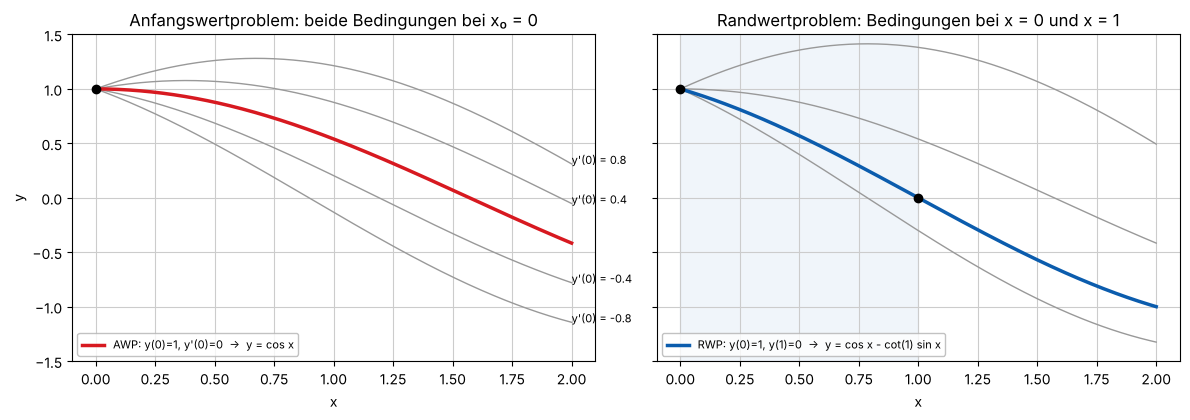

In [6]:
yf = sp.Function('y')
awp = sp.dsolve(yf(x).diff(x, 2) + yf(x), ics={yf(0): 1, yf(x).diff(x).subs(x, 0): 0})
rwp = sp.dsolve(yf(x).diff(x, 2) + yf(x), ics={yf(0): 1, yf(1): 0})
display(Markdown('**AWP:**'), awp, Markdown('**RWP:**'), rwp)

xs = np.linspace(0, 2, 300)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for steigung in (-0.8, -0.4, 0.4, 0.8):
    ax1.plot(xs, np.cos(xs) + steigung*np.sin(xs), color='0.6', linewidth=1)
    ax1.annotate(f"y'(0) = {steigung:g}", (2, np.cos(2) + steigung*np.sin(2)), fontsize=8)
ax1.plot(xs, np.cos(xs), color='#d71920', linewidth=2.5, label="AWP: y(0)=1, y'(0)=0  ->  y = cos x")
ax1.plot(0, 1, 'ko')
ax1.set(title='Anfangswertproblem: beide Bedingungen bei x₀ = 0', xlabel='x', ylabel='y', ylim=(-1.5, 1.5))
ax1.legend(loc='lower left', fontsize=8)

f_rwp = sp.lambdify(x, rwp.rhs, 'numpy')
for B in (-1.0, 0.0, 1.0):
    ax2.plot(xs, np.cos(xs) + B*np.sin(xs), color='0.6', linewidth=1)
ax2.plot(xs, f_rwp(xs), color='#0b5cad', linewidth=2.5, label='RWP: y(0)=1, y(1)=0  ->  y = cos x - cot(1) sin x')
ax2.plot([0, 1], [1, 0], 'ko')
ax2.axvspan(0, 1, color='#0b5cad', alpha=0.06)
ax2.set(title='Randwertproblem: Bedingungen bei x = 0 und x = 1', xlabel='x')
ax2.legend(loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()

**Merke:**

* Beim **AWP** sind Funktionswert und Steigung an einer Stelle gegeben; damit ist die Lösung eindeutig festgelegt.
* Beim **RWP** verteilen sich die Bedingungen auf die Intervallenden. Solche Aufgaben können **genau eine, keine oder unendlich viele** Lösungen haben.
* Typisch: AWP bei zeitabhängigen Vorgängen, RWP bei räumlichen bzw. stationären Problemen.

Die drei Fälle beim RWP lassen sich an $y'' + y = 0$ direkt nachrechnen. Setzt man $y = A\cos x + B\sin x$ in die beiden Randbedingungen ein, entsteht ein lineares Gleichungssystem für $A$ und $B$:

In [7]:
A_, B_ = sp.symbols('A B')
y_schar = A_*sp.cos(x) + B_*sp.sin(x)
faelle = [((0, 1), (1, 0)), ((0, 0), (sp.pi, 0)), ((0, 0), (sp.pi, 1))]
for (x0, y0), (x1, y1) in faelle:
    gls = [sp.Eq(y_schar.subs(x, x0), y0), sp.Eq(y_schar.subs(x, x1), y1)]
    loes = sp.solve(gls, [A_, B_], dict=True)
    if not loes:
        ergebnis = 'keine Lösung'
    elif len(loes[0]) < 2:
        ergebnis = f'unendlich viele Lösungen: {loes[0]}, die andere Konstante ist frei'
    else:
        ergebnis = f'genau eine Lösung: {loes[0]}'
    print(f'y({x0}) = {y0}, y({x1}) = {y1}:  {ergebnis}')

y(0) = 1, y(1) = 0:  genau eine Lösung: {A: 1, B: -cos(1)/sin(1)}
y(0) = 0, y(pi) = 0:  unendlich viele Lösungen: {A: 0}, die andere Konstante ist frei
y(0) = 0, y(pi) = 1:  keine Lösung


### Beispiel 1.2.5: Partielle Differentialgleichungen

Alle bisher betrachteten DGL sind **gewöhnlich**: Die gesuchte Funktion hängt von genau einer Variablen ab. Treten Ableitungen nach mehreren Variablen auf, spricht man von einer **partiellen** DGL:

* Wärmeleitungsgleichung: $\dfrac{\partial u}{\partial t} = a\,\dfrac{\partial^2 u}{\partial x^2}$ mit $u = u(x,t)$ (Ordnung 2)
* Wellengleichung: $\dfrac{\partial^2 u}{\partial t^2} = c^2\,\dfrac{\partial^2 u}{\partial x^2}$ mit $u = u(x,t)$ (Ordnung 2)
* Laplace-Gleichung: $\dfrac{\partial^2 u}{\partial x^2} + \dfrac{\partial^2 u}{\partial y^2} = 0$ mit $u = u(x,y)$ (Ordnung 2)

**Hinweis zur Notation:** $\partial^2 u/\partial x^2$ bedeutet zweimaliges Ableiten nach $x$; die 2 ist eine Ableitungsordnung, keine Potenz. $(\partial u/\partial x)^2$ ist das Quadrat der ersten Ableitung, $\partial^2 u/\partial x\,\partial t$ eine gemischte Ableitung.

### Beispiel 1.2.6: Anfangs-Randwertproblem

Für die Wärmeleitung in einem Stab der Länge $L$ mit $u = u(x,t)$:

* Anfangsbedingung: $u(x,0) = u_0(x)$ für $0 \le x \le L$ (Temperaturverteilung zum Zeitpunkt $t = 0$)
* Randbedingungen: $u(0,t) = T_1$ und $u(L,t) = T_2$ für $t \ge 0$ (Temperaturen an den Stabenden)

Da beide Arten von Bedingungen auftreten, spricht man von einem **Anfangs-Randwertproblem** (ARWP). Partielle DGL sind nicht Gegenstand dieser Vorlesung.

### Übersicht: Klassifikation von Differentialgleichungen

| Kriterium | Unterscheidung | Beispiel |
|---|---|---|
| Anzahl Variablen | gewöhnlich / partiell | $y' + 2xy = 0$ / $\partial u/\partial t = a\,\partial^2 u/\partial x^2$ |
| Höchste Ableitung | Ordnung $n$ | $y'' + y = 0 \to$ Ordnung 2 |
| Auftreten von $y, y', \dots$ | linear / nichtlinear | $y'' - xy = x$ / $(y')^2 - 2y = 3$ |
| Zusatzbedingungen | AWP / RWP / ARWP | $y(0)=1,\,y'(0)=0$ / $y(0)=1,\,y(1)=0$ |
| Struktur der rechten Seite | trennbar / ähnlich / … | $y' = f(y)\,g(x)$ (Abschnitt 1.3) / $y' = f(y/x)$ (Abschnitt 1.4) |

**Warum diese Einteilung?**

* Ordnung und Linearität sagen, wie viele Konstanten die Lösungsschar hat.
* Erst die Zusatzbedingungen (AWP oder RWP) legen die konkrete Lösung fest.
* Die Struktur der rechten Seite entscheidet über das Verfahren: Trennung der Variablen, Substitution $u = y/x$ oder ein Verfahren aus späteren Kapiteln.

Alle folgenden Beispiele dieses Notebooks sind gewöhnliche DGL erster Ordnung.

## 3. Abschnitt 1.3: Differentialgleichungen der Form $y'(x) = f(y)\cdot g(x)$

### Satz 1.3.1 (Separation der Variablen)

Die Lösung der Differentialgleichung
$$y'(x) = f\bigl(y(x)\bigr)\cdot g(x), \qquad y(x_0) = y_0$$
kann man durch Auflösen von
$$\int_{y_0}^{y(x)} \frac{dt}{f(t)} = \int_{x_0}^{x} g(s)\,ds$$
nach $y(x)$ erhalten. Man spricht von der **Trennung der Variablen** und nennt die DGL **separierbar** (trennbar).

**Bemerkung:**

* Die rechte Seite $F(x,y) = f(y)\cdot g(x)$ ist das Produkt zweier Funktionen **einer** Variablen: $g$ hängt nur von $x$ ab, $f$ nur von $y$.
* Herleitung: Man schreibt $y'$ als $\dfrac{dy}{dx}$, bringt alles mit $y$ auf die linke und alles mit $x$ auf die rechte Seite und integriert beide Seiten:
$$\frac{dy}{dx} = f(y)\,g(x) \quad\Longrightarrow\quad \frac{dy}{f(y)} = g(x)\,dx \quad\Longrightarrow\quad \int\frac{dy}{f(y)} = \int g(x)\,dx.$$

Die folgende Hilfsfunktion führt genau diese Schritte mit SymPy aus. Sie wird in den Beispielen unten verwendet.

In [8]:
def trennung_der_variablen(f, g, x0, y0, Y=sp.Symbol('Y', real=True), annahmen=None):
    """Löst y' = f(y) g(x), y(x0) = y0 nach Satz 1.3.1 (bestimmte Integration).

    f, g: SymPy-Lambdas, z. B. f = lambda y: y, g = lambda x: x
    Gibt alle Lösungszweige y(x) zurück und zeigt die Zwischenschritte.
    """
    s_, t_ = sp.symbols('s t_', real=True)
    links = sp.integrate(1/f(t_), (t_, y0, Y))
    rechts = sp.integrate(g(s_), (s_, x0, x))
    gleichung = sp.Eq(sp.simplify(links), sp.simplify(rechts))
    display(Markdown('Integrierte Gleichung $\\int_{y_0}^{y} dt/f(t) = \\int_{x_0}^{x} g(s)\\,ds$:'), gleichung)
    loesungen = sp.solve(gleichung, Y)
    return [sp.simplify(l) for l in loesungen]

### Beispiel 1.3.2: $y' = 2\sqrt{y}$

$$\frac{dy}{dx} = 2\sqrt{y} \;\Longleftrightarrow\; \frac{dy}{\sqrt{y}} = 2\,dx \;\Longrightarrow\; \int\frac{dy}{\sqrt{y}} = \int 2\,dx \;\Longrightarrow\; 2\sqrt{y} + c_1 = 2x + c_2$$

Auf jeder Seite entsteht eine Konstante; $c_1$ und $c_2$ werden zusammengefasst. Nach Division durch 2:
$$\sqrt{y} = x + c \;\Longrightarrow\; y = (x+c)^2 \qquad (\text{für } x + c \ge 0).$$

**Beachte:** $y \equiv 0$ ist **zusätzlich** Lösung. Die Division durch $\sqrt{y}$ setzt $y > 0$ voraus (siehe Nachtrag unten).

Die Probe zeigt einen Punkt, der beim Rechnen leicht übersehen wird: $\sqrt{(x+c)^2} = |x+c|$. Deshalb erfüllt $(x+c)^2$ die DGL nur dort, wo $x + c \ge 0$ ist.

Residuum allgemein: 2*c + 2*x - 2*Abs(c + x)
Probe für x + c > 0: Residuum = 0  -> ok
Probe y ≡ 0: Residuum = 0  -> ok


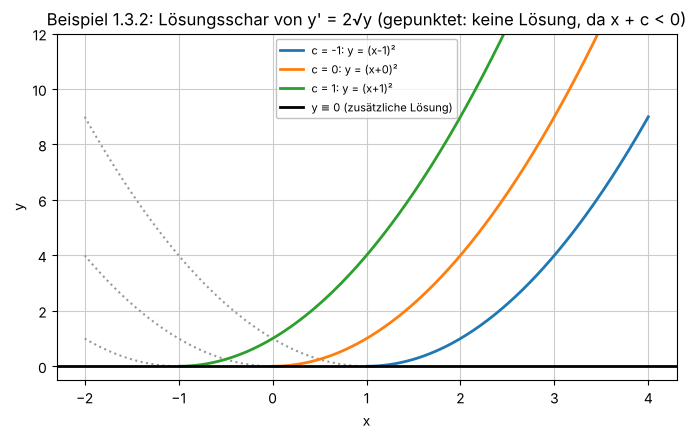

In [9]:
c_ = sp.symbols('c', real=True)
y_132 = (x + c_)**2
residuum = sp.diff(y_132, x) - 2*sp.sqrt(y_132)
print('Residuum allgemein:', sp.simplify(residuum))

u_pos = sp.symbols('u', positive=True)            # u = x + c > 0
pruefe('für x + c > 0', residuum.subs(x, u_pos - c_))
pruefe('y ≡ 0', sp.diff(sp.Integer(0), x) - 2*sp.sqrt(0))

xs = np.linspace(-2, 4, 400)
for c_wert in (-1, 0, 1):
    ast = xs[xs + c_wert >= 0]
    plt.plot(ast, (ast + c_wert)**2, linewidth=2, label=f'c = {c_wert}: y = (x{c_wert:+d})²')
    plt.plot(xs[xs + c_wert < 0], (xs[xs + c_wert < 0] + c_wert)**2, ':', color='0.6')
plt.axhline(0, color='black', linewidth=2, label='y ≡ 0 (zusätzliche Lösung)')
plt.ylim(-0.5, 12); plt.xlabel('x'); plt.ylabel('y')
plt.title("Beispiel 1.3.2: Lösungsschar von y' = 2√y (gepunktet: keine Lösung, da x + c < 0)")
plt.legend(fontsize=8); plt.show()

### Beispiel 1.3.3: $y' = x\cdot y$, $\;y(0) = 1$

**Lösung mit bestimmter Integration (Satz 1.3.1):** Mit $f(y) = y$, $g(x) = x$ und den Grenzen aus der Anfangsbedingung ($x_0 = 0$, $y_0 = 1$):
$$\int_1^y \frac{ds}{s} = \int_0^x t\,dt \;\Longrightarrow\; \bigl[\ln|s|\bigr]_1^y = \Bigl[\tfrac12 t^2\Bigr]_0^x \;\Longrightarrow\; \ln|y| - \ln 1 = \tfrac12 x^2.$$
Entlogarithmieren liefert $y(x) = e^{0{,}5x^2}$. Die additive Konstante ist durch die Grenzen bereits festgelegt (hier $\ln 1 = 0$).

**Probe:** $y'(x) = 0{,}5\cdot 2x\cdot e^{0{,}5x^2} = x\,e^{0{,}5x^2} = x\cdot y$ für alle $x\in\mathbb{R}$.

In [10]:
loes_133 = trennung_der_variablen(lambda yy: yy, lambda xx: xx, 0, 1, Y=sp.Symbol('Y', positive=True))
y_133 = loes_133[0]
display(sp.Eq(sp.Symbol('y(x)'), y_133))
pruefe("y' - x y", sp.diff(y_133, x) - x*y_133)
print('Anfangswert y(0) =', y_133.subs(x, 0))

Integrierte Gleichung $\int_{y_0}^{y} dt/f(t) = \int_{x_0}^{x} g(s)\,ds$:

Probe y' - x y: Residuum = 0  -> ok
Anfangswert y(0) = 1


#### Beispiel 1.3.3 (Fortsetzung): Alternative Rechnung mit unbestimmtem Integral

Statt mit Grenzen kann man unbestimmt integrieren und die Konstante erst am Schluss festlegen.

1. Trennen der Variablen (für $y \ne 0$): $\dfrac{dy}{y} = x\,dx$
2. Unbestimmt integrieren: $\ln|y| + c_1 = 0{,}5x^2 + c_2 \;\Rightarrow\; \ln|y| = 0{,}5x^2 + c$ mit $c = c_2 - c_1$
3. Entlogarithmieren: $|y| = e^{0{,}5x^2 + c} = e^c\cdot e^{0{,}5x^2} \;\Rightarrow\; y(x) = C\cdot e^{0{,}5x^2}$ mit $C = \pm e^c$.
   Zusätzlich ist $y \equiv 0$ Lösung; sie entspricht $C = 0$, was beim Teilen durch $y$ ausgeschlossen wurde.
4. Anfangsbedingung einsetzen: $y(0) = C\cdot e^0 = C = 1 \;\Rightarrow\; y(x) = e^{0{,}5x^2}$

**Vergleich:** Bei der bestimmten Integration ist die Konstante wegen $\ln 1 = 0$ automatisch erledigt; beim unbestimmten Integral trägt man die allgemeine Lösung mit $C$ mit und bestimmt $C$ im letzten Schritt. Das Ergebnis ist identisch. SymPys `dsolve` geht den zweiten Weg:

In [11]:
yf = sp.Function('y')
allgemein = sp.dsolve(sp.Eq(yf(x).diff(x), x*yf(x)))
speziell = sp.dsolve(sp.Eq(yf(x).diff(x), x*yf(x)), ics={yf(0): 1})
display(allgemein, speziell)

#### Richtungsfeld zu Beispiel 1.3.3: $y' = x\cdot y$

Jeder Strich zeigt die von der DGL vorgeschriebene Steigung.

**So liest man das Richtungsfeld:**

* Die DGL gibt in jedem Punkt $(x,y)$ nur die **Steigung** vor, nicht die Lösung selbst. Folgt man den Strichen, erhält man den Verlauf einer Lösungskurve: Die Gestalt lässt sich ablesen, die Formel nicht.
* Auf den Achsen ($x = 0$ oder $y = 0$) ist $y' = 0$: Dort sind die Striche waagerecht.
* Links der $y$-Achse fallen die Striche (für $y>0$), rechts steigen sie: Die Lösungen haben bei $x = 0$ ihr Minimum.
* Die Steigung ist proportional zu $y$ und wächst nach außen: exponentielles Verhalten, kein Polynom. Den genauen Exponenten $0{,}5x^2$ liefert erst die Rechnung.
* Die Anfangsbedingung $y(0) = 1$ wählt genau eine Kurve der Schar $y = C\,e^{0{,}5x^2}$ aus, hier $C = 1$.

Alle Kurven der Schar sind zueinander gestreckt bzw. gestaucht; sie schneiden sich nie. **Durch jeden Punkt der Ebene geht genau eine Lösungskurve.**

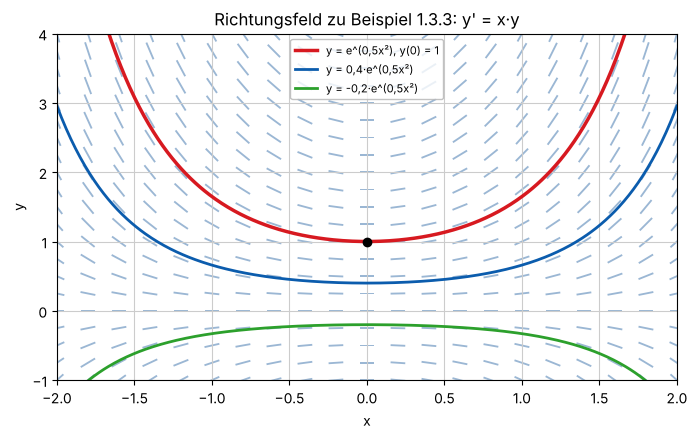

In [12]:
xs = np.linspace(-2, 2, 400)
richtungsfeld(lambda X, Y: X*Y, (-2, 2), (-1, 4))
plt.plot(xs, np.exp(0.5*xs**2), color='#d71920', linewidth=2.5, label='y = e^(0,5x²), y(0) = 1')
plt.plot(xs, 0.4*np.exp(0.5*xs**2), color='#0b5cad', linewidth=2, label='y = 0,4·e^(0,5x²)')
plt.plot(xs, -0.2*np.exp(0.5*xs**2), color='C2', linewidth=2, label='y = -0,2·e^(0,5x²)')
plt.plot(0, 1, 'ko')
plt.xlabel('x'); plt.ylabel('y'); plt.title("Richtungsfeld zu Beispiel 1.3.3: y' = x·y")
plt.legend(loc='upper center', fontsize=8); plt.show()

**Interaktiv:** Wählen Sie einen Anfangspunkt $(x_0, y_0)$. Die Lösung durch diesen Punkt ist $y = y_0\,e^{(x^2 - x_0^2)/2}$. Beobachten Sie, dass die Kurve stets tangential zu den Strichen verläuft und sich nie mit der Kurve durch $(0,1)$ schneidet.

Output()

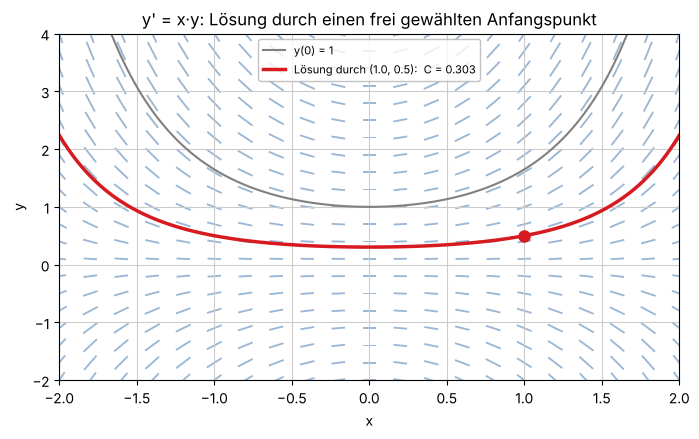

In [13]:
def zeige_richtungsfeld_133(x0=1.0, y0=0.5):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    richtungsfeld(lambda X, Y: X*Y, (-2, 2), (-2, 4), ax=ax)
    xs = np.linspace(-2, 2, 400)
    ax.plot(xs, np.exp(0.5*xs**2), color='0.5', linewidth=1.5, label='y(0) = 1')
    ax.plot(xs, y0*np.exp((xs**2 - x0**2)/2), color='#d71920', linewidth=2.5,
            label=f'Lösung durch ({x0:.1f}, {y0:.1f}):  C = {y0*np.exp(-x0**2/2):.3f}')
    ax.plot(x0, y0, 'o', color='#d71920', markersize=8)
    ax.set(xlabel='x', ylabel='y', title="y' = x·y: Lösung durch einen frei gewählten Anfangspunkt")
    ax.legend(loc='upper center', fontsize=8); plt.show()


x0_regler = widgets.FloatSlider(value=1.0, min=-2, max=2, step=0.1, description='x₀', continuous_update=False)
y0_regler = widgets.FloatSlider(value=0.5, min=-2, max=3, step=0.1, description='y₀', continuous_update=False)
display(widgets.HBox([x0_regler, y0_regler]),
        widgets.interactive_output(zeige_richtungsfeld_133, {'x0': x0_regler, 'y0': y0_regler}))

# Statische Vorschau für GitHub.
zeige_richtungsfeld_133()

#### Nachtrag zu Beispiel 1.3.2: Warum $y \equiv 0$ dazugehört

Das AWP $y' = 2\sqrt{y}$ mit $y(0) = 0$ hat **unendlich viele** Lösungen. (Die Anfangsbedingung ist hier nur zur Veranschaulichung ergänzt; Beispiel 1.3.2 selbst gibt keine vor.)

**Warum ist die Lösung hier nicht eindeutig?**

* Die Trennung der Variablen verlangt die Division durch $\sqrt{y}$, und das setzt $y > 0$ voraus. Bei $y = 0$ ist dieser Schritt nicht erlaubt, und $y \equiv 0$ fällt aus der Rechnung heraus.
* **Lösungsfamilie:** Für jedes $a \ge 0$ löst
$$y_a(x) = \begin{cases} 0 & x \le a \\ (x-a)^2 & x \ge a\end{cases}$$
das Problem. Am Übergang $x = a$ ist die Steigung von beiden Seiten 0, die Funktion dort also differenzierbar.
* **Anschaulich:** Die Lösung darf beliebig lange bei 0 „warten“ und irgendwann losstarten; die DGL legt $a$ nicht fest. Grenzfälle: $a = 0$ gibt $y = x^2$, „$a\to\infty$“ gibt $y \equiv 0$.
* Für $y(0) = y_0 > 0$ tritt das Problem nicht auf: Dort ist die Lösung eindeutig, solange $y > 0$ bleibt.

**Merke:** Vor dem Teilen durch einen Ausdruck in $y$ immer prüfen, ob dieser null werden kann. Die Nullstellen liefern oft zusätzliche (stationäre) Lösungen.

Mit dem Schieberegler wählen Sie den „Startzeitpunkt“ $a$. Jede Wahl liefert eine gültige Lösung des AWP.

Ableitung rechts bei x = a: 0  (links: 0)
Probe rechter Ast für x > a: Residuum = 0  -> ok


FloatSlider(value=1.0, continuous_update=False, description='a', max=3.0)

Output()

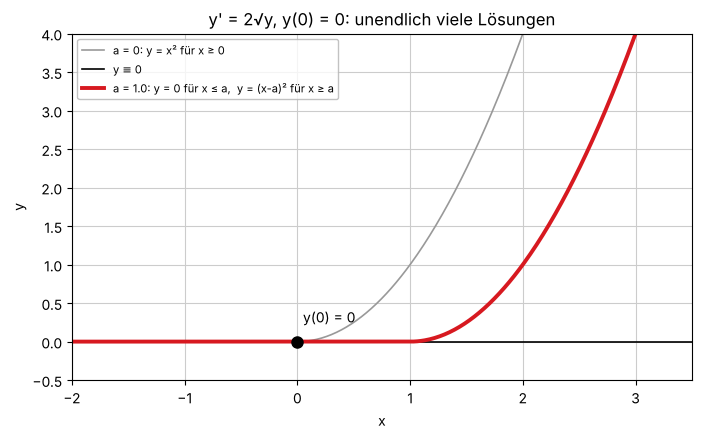

In [14]:
a_sym = sp.symbols('a', nonnegative=True)
rechter_ast = (x - a_sym)**2
print("Ableitung rechts bei x = a:", sp.diff(rechter_ast, x).subs(x, a_sym), " (links: 0)")
u_pos = sp.symbols('u', positive=True)
pruefe("rechter Ast für x > a", (sp.diff(rechter_ast, x) - 2*sp.sqrt(rechter_ast)).subs(x, a_sym + u_pos))


def zeige_nichteindeutigkeit(a=1.0):
    xs = np.linspace(-2, 3.5, 500)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(xs, np.where(xs >= 0, xs**2, 0), color='0.6', linewidth=1.2, label='a = 0: y = x² für x ≥ 0')
    ax.axhline(0, color='black', linewidth=1.2, label='y ≡ 0')
    ax.plot(xs, np.where(xs >= a, (xs - a)**2, 0), color='#d71920', linewidth=2.8,
            label=f'a = {a:.1f}: y = 0 für x ≤ a,  y = (x-a)² für x ≥ a')
    ax.plot(0, 0, 'ko', markersize=8); ax.annotate('y(0) = 0', (0.05, 0.25))
    ax.set(xlim=(-2, 3.5), ylim=(-0.5, 4), xlabel='x', ylabel='y',
           title="y' = 2√y, y(0) = 0: unendlich viele Lösungen")
    ax.legend(loc='upper left', fontsize=8); plt.show()


a_regler = widgets.FloatSlider(value=1.0, min=0, max=3, step=0.1, description='a', continuous_update=False)
display(a_regler, widgets.interactive_output(zeige_nichteindeutigkeit, {'a': a_regler}))

# Statische Vorschau für GitHub.
zeige_nichteindeutigkeit()

### Beispiel 1.3.4: $y' = x^2 + x^2y^2$

Mit $y' = x^2(1 + y^2)$ sieht man, dass die DGL die Form $y' = f(y)\cdot g(x)$ hat:
$$\frac{dy}{dx} = x^2(1+y^2) \;\Rightarrow\; \int\frac{dy}{1+y^2} = \int x^2\,dx \;\Rightarrow\; \arctan y = \frac{x^3}{3} + c \;\Rightarrow\; y = \tan\Bigl(\frac{x^3}{3} + c\Bigr)$$
($\int\frac{dy}{1+y^2} = \arctan y$ ist ein bekanntes Stammintegral.)

**Achtung, Definitionsbereich:** $\tan$ hat Polstellen bei $\pm\pi/2$. Eine Lösung existiert daher nur, solange $\bigl|\tfrac{x^3}{3} + c\bigr| < \tfrac{\pi}{2}$ bleibt. Die Lösungskurven laufen in endlicher Zeit nach $\pm\infty$ – typisch für nichtlineare DGL, bei linearen DGL tritt das nicht auf.

Probe y' - x²(1 + y²): Residuum = 0  -> ok


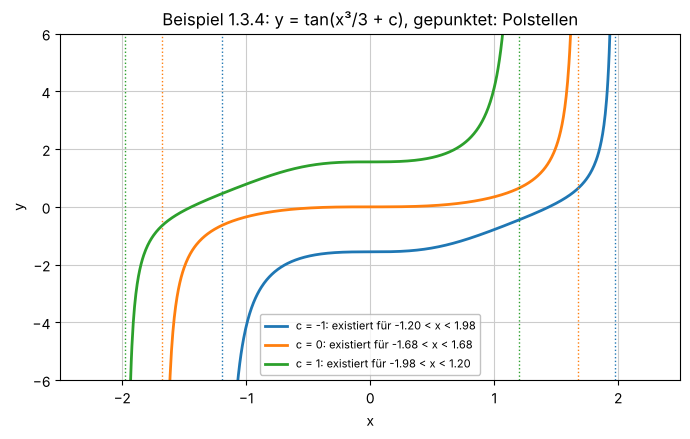

In [15]:
y_134 = sp.tan(x**3/3 + c_)
pruefe("y' - x²(1 + y²)", sp.diff(y_134, x) - x**2*(1 + y_134**2))

for c_wert in (-1.0, 0.0, 1.0):
    # Existenzintervall: -pi/2 < x^3/3 + c < pi/2
    x_links = np.cbrt(3*(-np.pi/2 - c_wert)); x_rechts = np.cbrt(3*(np.pi/2 - c_wert))
    xs = np.linspace(x_links + 1e-3, x_rechts - 1e-3, 600)
    linie, = plt.plot(xs, np.tan(xs**3/3 + c_wert), linewidth=2,
                      label=f'c = {c_wert:g}: existiert für {x_links:.2f} < x < {x_rechts:.2f}')
    for xr in (x_links, x_rechts):
        plt.axvline(xr, color=linie.get_color(), linestyle=':', linewidth=1)
plt.ylim(-6, 6); plt.xlim(-2.5, 2.5); plt.xlabel('x'); plt.ylabel('y')
plt.title("Beispiel 1.3.4: y = tan(x³/3 + c), gepunktet: Polstellen")
plt.legend(fontsize=8); plt.show()

### Beispiel 1.3.5: $y' = xy^2 + x$, $\;y(0) = 1$

Die DGL lässt sich als $y' = x\,(y^2 + 1)$ schreiben, sie hat also getrennte Variablen:
$$\frac{y'}{y^2+1} = x \;\Longrightarrow\; \int_0^x \frac{y'(t)}{y(t)^2+1}\,dt = \int_1^y \frac{1}{s^2+1}\,ds = \int_0^x t\,dt$$
(Substitution $s = y(t)$, $ds = y'(t)\,dt$; Grenzen aus $y(0) = 1$: $t: 0\to x$, $s: 1\to y$.)
$$\arctan y - \arctan 1 = \tfrac12 x^2 \;\Longrightarrow\; y = \tan\Bigl(\tfrac12 x^2 + \tfrac{\pi}{4}\Bigr).$$
Die Lösung existiert, solange $\tfrac12 x^2 + \tfrac{\pi}{4} < \tfrac{\pi}{2}$, also für $|x| < \sqrt{\pi/2} \approx 1{,}25$.

Integrierte Gleichung $\int_{y_0}^{y} dt/f(t) = \int_{x_0}^{x} g(s)\,ds$:

Probe y' - (x y² + x): Residuum = 0  -> ok
y(0) = 1


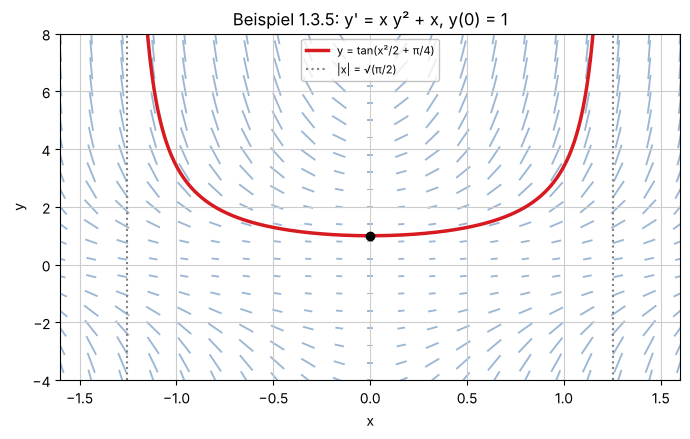

In [16]:
loes_135 = trennung_der_variablen(lambda yy: yy**2 + 1, lambda xx: xx, 0, 1)
y_135 = loes_135[0]
display(sp.Eq(sp.Symbol('y(x)'), y_135))
pruefe("y' - (x y² + x)", sp.diff(y_135, x) - (x*y_135**2 + x))
print('y(0) =', y_135.subs(x, 0))

grenze = np.sqrt(np.pi/2)
xs = np.linspace(-grenze + 1e-3, grenze - 1e-3, 500)
richtungsfeld(lambda X, Y: X*(Y**2 + 1), (-1.6, 1.6), (-4, 8))
plt.plot(xs, np.tan(xs**2/2 + np.pi/4), color='#d71920', linewidth=2.5, label='y = tan(x²/2 + π/4)')
plt.axvline(grenze, color='gray', linestyle=':'); plt.axvline(-grenze, color='gray', linestyle=':', label='|x| = √(π/2)')
plt.plot(0, 1, 'ko')
plt.xlabel('x'); plt.ylabel('y'); plt.title("Beispiel 1.3.5: y' = x y² + x, y(0) = 1")
plt.legend(loc='upper center', fontsize=8); plt.show()

### Beispiel 1.3.6: Lösung von Beispiel 1.1.1 (Kaffee)

Wir lösen das Problem mit der Trennung der Variablen:
$$\frac{dT}{dt} = -k\,(T - U) \;\Longleftrightarrow\; \frac{dT}{T - U} = -k\,dt \;\Longrightarrow\; \ln|T - U| = -k\,t + c,\quad c\in\mathbb{R}$$
$$\Longleftrightarrow\; |T - U| = e^c\cdot e^{-kt}.$$
Auf die Betragsstriche kann man verzichten, wenn man $\pm e^c$ als neue Konstante $C \in\mathbb{R}$ schreibt:
$$T(t) = C\,e^{-kt} + U.$$

**Konstanten bestimmen:**

* $T(0) = C + 22 = 85 \;\Rightarrow\; C = 63$
* $T(10) = 63\,e^{-10k} + 22 = 71 \;\Leftrightarrow\; e^{-10k} = \tfrac{49}{63} \;\Leftrightarrow\; k = \dfrac{\ln(49/63)}{-10} \approx 0{,}0251\;\mathrm{min}^{-1}$

Somit lautet die Temperaturfunktion $T(t) = 63\,e^{-0{,}0251\,t} + 22$.

* **60 °C:** $e^{-0{,}0251\,t} = \tfrac{38}{63} \approx 0{,}6032 \;\Rightarrow\; t = \dfrac{\ln 0{,}6032}{-0{,}0251} \approx 20{,}1$ min. Die Mitarbeiterin hätte bis ca. 9:20 Uhr warten müssen, nach ihrer Messung also noch etwa 10 Minuten.
* **30 °C:** $e^{-0{,}0251\,t} = \tfrac{8}{63} \approx 0{,}1270 \;\Rightarrow\; t \approx 82{,}1$ min, also gegen 10:22 Uhr.

In [17]:
T = sp.Function('T')
k_s, C_s = sp.symbols('k C', real=True)
U = 22
allg = sp.dsolve(sp.Eq(T(t).diff(t), -k_s*(T(t) - U)))
display(Markdown('**Allgemeine Lösung (SymPy):**'), allg)

T_t = allg.rhs.subs('C1', C_s)
C_wert = sp.solve(sp.Eq(T_t.subs(t, 0), 85), C_s)[0]
T_t = T_t.subs(C_s, C_wert)
k_wert = sp.solve(sp.Eq(T_t.subs(t, 10), 71), k_s)[0]
T_t = T_t.subs(k_s, k_wert)
assert sp.simplify(k_wert - sp.log(sp.Rational(63, 49))/10) == 0
display(Markdown(f'$C = {C_wert}$,  $k = \\tfrac{{1}}{{10}}\\ln\\tfrac{{63}}{{49}} \\approx {float(k_wert):.4f}$'), sp.Eq(T(t), T_t))
pruefe("T' + k (T - U)", sp.diff(T_t, t) + k_wert*(T_t - U))

t60 = sp.solve(sp.Eq(T_t, 60), t)[0]
t30 = sp.solve(sp.Eq(T_t, 30), t)[0]
for ziel, tz in ((60, t60), (30, t30)):
    minuten = float(tz)
    uhr = f'{9 + int((minuten) // 60)}:{int(round(minuten)) % 60:02d}'
    print(f'T(t) = {ziel} °C nach t = {minuten:.1f} min, also gegen {uhr} Uhr')

**Allgemeine Lösung (SymPy):**

$C = 63$,  $k = \tfrac{1}{10}\ln\tfrac{63}{49} \approx 0.0251$

Probe T' + k (T - U): Residuum = 0  -> ok


T(t) = 60 °C nach t = 20.1 min, also gegen 9:20 Uhr
T(t) = 30 °C nach t = 82.1 min, also gegen 10:22 Uhr


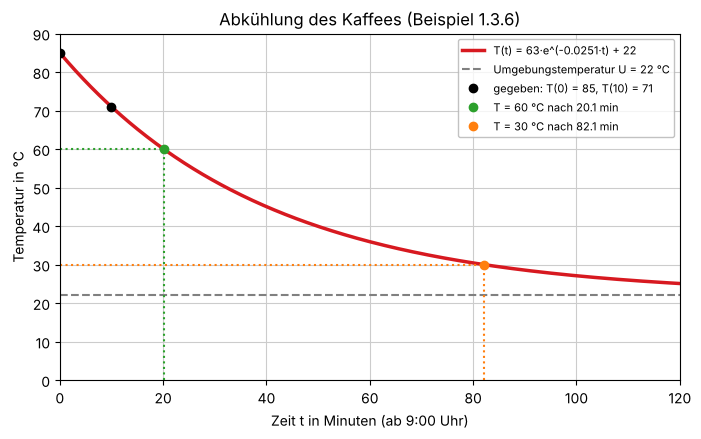

In [18]:
f_T = sp.lambdify(t, T_t, 'numpy')
ts = np.linspace(0, 120, 400)
plt.plot(ts, f_T(ts), color='#d71920', linewidth=2.5, label=f'T(t) = 63·e^(-{float(k_wert):.4f}·t) + 22')
plt.axhline(22, color='gray', linestyle='--', label='Umgebungstemperatur U = 22 °C')
plt.plot([0, 10], [85, 71], 'ko', label='gegeben: T(0) = 85, T(10) = 71')
for ziel, tz, farbe in ((60, float(t60), 'C2'), (30, float(t30), 'C1')):
    plt.plot([tz, tz], [0, ziel], ':', color=farbe); plt.plot([0, tz], [ziel, ziel], ':', color=farbe)
    plt.plot(tz, ziel, 'o', color=farbe, label=f'T = {ziel} °C nach {tz:.1f} min')
plt.ylim(0, 90); plt.xlim(0, 120)
plt.xlabel('Zeit t in Minuten (ab 9:00 Uhr)'); plt.ylabel('Temperatur in °C')
plt.title('Abkühlung des Kaffees (Beispiel 1.3.6)'); plt.legend(fontsize=8); plt.show()

**Interaktiv:** Wie ändert sich die Wartezeit, wenn der Raum kühler oder wärmer ist oder die Messung um 9:10 Uhr anders ausfällt? Der Abkühlungskoeffizient $k$ wird jeweils aus der Messung neu berechnet: $k = \ln\bigl(\tfrac{T_0 - U}{T_{10} - U}\bigr)/10$.

Output()

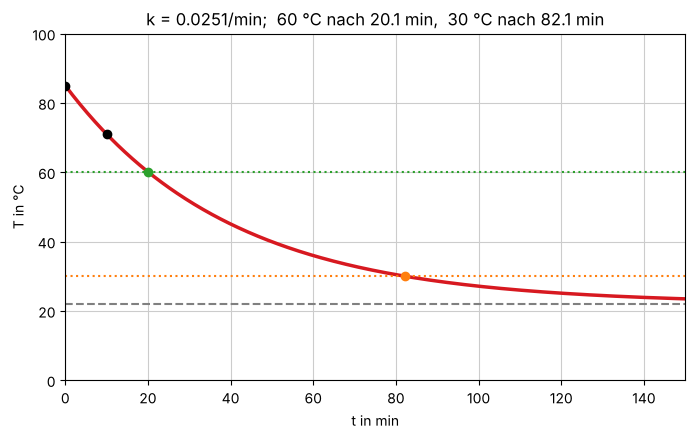

In [19]:
def zeige_kaffee(U=22.0, T0=85.0, T10=71.0):
    if not (U < T10 < T0):
        print('Bitte U < T(10) < T(0) wählen.'); return
    k = np.log((T0 - U)/(T10 - U))/10
    ts = np.linspace(0, 150, 500)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(ts, (T0 - U)*np.exp(-k*ts) + U, color='#d71920', linewidth=2.5)
    ax.axhline(U, color='gray', linestyle='--')
    ax.plot([0, 10], [T0, T10], 'ko')
    text = []
    for ziel, farbe in ((60, 'C2'), (30, 'C1')):
        if U < ziel < T0:
            tz = np.log((T0 - U)/(ziel - U))/k
            ax.axhline(ziel, color=farbe, linestyle=':'); ax.plot(tz, ziel, 'o', color=farbe)
            text.append(f'{ziel} °C nach {tz:.1f} min')
        else:
            text.append(f'{ziel} °C wird nie erreicht')
    ax.set(ylim=(0, 100), xlim=(0, 150), xlabel='t in min', ylabel='T in °C',
           title=f'k = {k:.4f}/min;  ' + ',  '.join(text))
    plt.show()


regler = dict(
    U=widgets.FloatSlider(value=22, min=0, max=40, step=1, description='U', continuous_update=False),
    T0=widgets.FloatSlider(value=85, min=60, max=100, step=1, description='T(0)', continuous_update=False),
    T10=widgets.FloatSlider(value=71, min=41, max=95, step=1, description='T(10)', continuous_update=False),
)
display(widgets.HBox(list(regler.values())), widgets.interactive_output(zeige_kaffee, regler))

# Statische Vorschau für GitHub.
zeige_kaffee()

### Lösungsmethode 1.3.7 (Trennung der Variablen)

1. Ersetzen von $y'(x)$ durch die Schreibweise $\dfrac{dy}{dx}$.
2. Trennung der Variablen in $\dfrac{dy}{dx} = f(y)\,g(x)$ liefert $\dfrac{dy}{f(y)} = g(x)\,dx$.
3. Integration beider Seiten: $\displaystyle\int\frac{dy}{f(y)} = \int g(x)\,dx$.
4. Die Anfangsbedingung $y(x_0) = y_0$ liefert die konkrete Lösung $\displaystyle\int_{y_0}^{y}\frac{dt}{f(t)} = \int_{x_0}^{x} g(s)\,ds$.
5. Soweit möglich: Auflösen nach $y(x)$, um eine explizite Darstellung zu erhalten.

**Ergebnis:** $y(x)$ mit bereits festgelegter Konstante; kein nachträgliches Bestimmen von $C$ nötig.

**Nicht vergessen:** Nullstellen von $f(y)$ liefern zusätzliche konstante Lösungen $y \equiv y^*$ (Nachtrag zu Beispiel 1.3.2).

Die Grafik zeigt noch einmal die Lösungsschar $y = (x+c)^2$ aus Beispiel 1.3.2: Die Anfangsbedingung wählt **eine** Kurve aus.

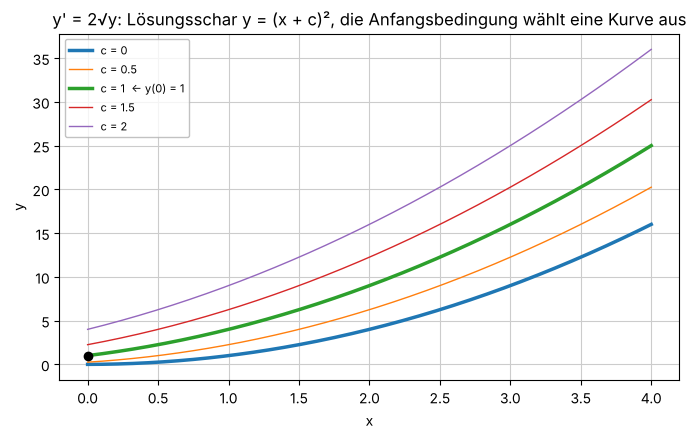

In [20]:
xs = np.linspace(0, 4, 300)
for c_wert in (0, 0.5, 1, 1.5, 2):
    plt.plot(xs, (xs + c_wert)**2, linewidth=2.5 if c_wert in (0, 1) else 1,
             label=f'c = {c_wert:g}' + ('  <- y(0) = 1' if c_wert == 1 else ''))
plt.plot(0, 1, 'ko')
plt.xlabel('x'); plt.ylabel('y'); plt.title("y' = 2√y: Lösungsschar y = (x + c)², die Anfangsbedingung wählt eine Kurve aus")
plt.legend(fontsize=8); plt.show()

## 4. Abschnitt 1.4: Differentialgleichungen der Form $y'(x) = f\!\left(\dfrac{y}{x}\right)$

### Satz 1.4.1

Es sei $f$ auf $(a,b)$ stetig und $f(u) - u \ne 0$ für $a < u < b$. Dann gibt es für jeden Punkt $(x_0, y_0)$ mit $a < \dfrac{y_0}{x_0} < b$ eine Lösung der Gleichung $y' = f\!\left(\dfrac{y}{x}\right)$ mit $y(x_0) = y_0$.

Diese Lösung erhält man durch Einführung der neuen Variablen $u = \dfrac{y}{x}$ und Lösung der DGL
$$u' = \frac{f(u) - u}{x}\qquad\text{mit}\qquad u(x_0) = \frac{y_0}{x_0}.$$

**Bemerkung:** DGL der Form $y' = f(y/x)$ heißen **gleichgradige** DGL oder **Ähnlichkeitsdifferentialgleichungen**. Man löst sie mit einer geeigneten Substitution.

**Beweisidee:** Aus $y(x) = u(x)\cdot x$ folgt mit der Produktregel $y'(x) = u'(x)\cdot x + u(x)$. Eingesetzt in $y' = f(y/x)$:
$$u'(x)\cdot x + u(x) = f(u) \quad\Longleftrightarrow\quad u' = \frac{f(u) - u}{x}.$$
Das ist eine Gleichung mit getrennten Variablen (Abschnitt 1.3).

**Woran erkennt man diese Form?** Die rechte Seite $g(x,y)$ muss **homogen vom Grad 0** sein: $g(\lambda x, \lambda y) = g(x,y)$ für alle $\lambda \ne 0$. Mit $\lambda = 1/x$ folgt $g(x,y) = g(1, y/x) =: f(y/x)$. Praktisch: Zähler und Nenner durch die höchste $x$-Potenz kürzen; bleibt nur $y/x$ stehen, ist $u = y/x$ anwendbar.

**Warum $u = y/x$?** Auf jeder Ursprungsgeraden $y = u\cdot x$ ist $y/x = u$ konstant, also auch die Steigung $f(u)$. Das Richtungsfeld ist entlang jeder Ursprungsgeraden konstant.

Die folgende Zelle prüft den Homogenitätstest für die Beispiele dieses Abschnitts – und für ein Gegenbeispiel.

In [21]:
X_, Y_, L_ = sp.symbols('x y lambda', positive=True)

def ist_aehnlichkeits_dgl(g):
    """Test: g(λx, λy) = g(x, y) für alle λ?  Liefert True/False und f(u) = g(1, u)."""
    homogen = sp.simplify(g(L_*X_, L_*Y_) - g(X_, Y_)) == 0
    u = sp.Symbol('u')
    return homogen, sp.simplify(g(1, u)) if homogen else None

tests = {
    "Bsp. 1.4.2: (9x² + 3y²)/(2xy)": lambda X, Y: (9*X**2 + 3*Y**2)/(2*X*Y),
    "Bsp. 1.4.3: y/x + cos²(y/x)":   lambda X, Y: Y/X + sp.cos(Y/X)**2,
    "Bsp. 1.4.5: (x + y)/x":         lambda X, Y: (X + Y)/X,
    "Bsp. 1.4.6: y/x + (y/x)²":      lambda X, Y: Y/X + (Y/X)**2,
    "Gegenbeispiel: x + y":          lambda X, Y: X + Y,
}
for name, g in tests.items():
    homogen, f_u = ist_aehnlichkeits_dgl(g)
    print(f'{name:34s} homogen vom Grad 0: {str(homogen):5s}', f'  f(u) = {f_u}' if homogen else '')

Bsp. 1.4.2: (9x² + 3y²)/(2xy)      homogen vom Grad 0: True    f(u) = 3*(u**2 + 3)/(2*u)
Bsp. 1.4.3: y/x + cos²(y/x)        homogen vom Grad 0: True    f(u) = u + cos(u)**2
Bsp. 1.4.5: (x + y)/x              homogen vom Grad 0: True    f(u) = u + 1
Bsp. 1.4.6: y/x + (y/x)²           homogen vom Grad 0: True    f(u) = u*(u + 1)
Gegenbeispiel: x + y               homogen vom Grad 0: False 


### Beispiel 1.4.2: $y' = \dfrac{9x^2 + 3y^2}{2xy}$ für $x > 0$

Zähler und Nenner haben jeweils Grad 2 (bei $2xy$: $1 + 1 = 2$). Division durch $x^2$:
$$y' = \frac{9 + 3\left(\frac{y}{x}\right)^2}{2\,\frac{y}{x}}.$$
Mit $y = u\,x$, $y' = u'x + u$:
$$u'x + u = \frac{9 + 3u^2}{2u} \;\Longleftrightarrow\; u' = \frac{\frac{9 + 3u^2}{2u} - u}{x} = \frac{9 + u^2}{2u\,x}.$$
Trennung der Variablen:
$$\int\frac{2u\,du}{9 + u^2} = \int\frac{dx}{x} \;\Longrightarrow\; \ln|9 + u^2| = \ln|x| + \ln|C| \;\Longleftrightarrow\; 9 + u^2 = Cx$$
(Substitution im linken Integral: $z = 9 + u^2$, $dz = 2u\,du$, also $\int\frac{dz}{z} = \ln|z|$.)
$$u = \pm\sqrt{Cx - 9} \;\Longrightarrow\; y = \pm x\sqrt{Cx - 9}\qquad(Cx > 9).$$

DGL für $u$ nach der Substitution:

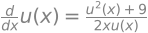

Probe y = +x·sqrt(Cx - 9): Residuum = 0  -> ok
Probe y = -x·sqrt(Cx - 9): Residuum = 0  -> ok


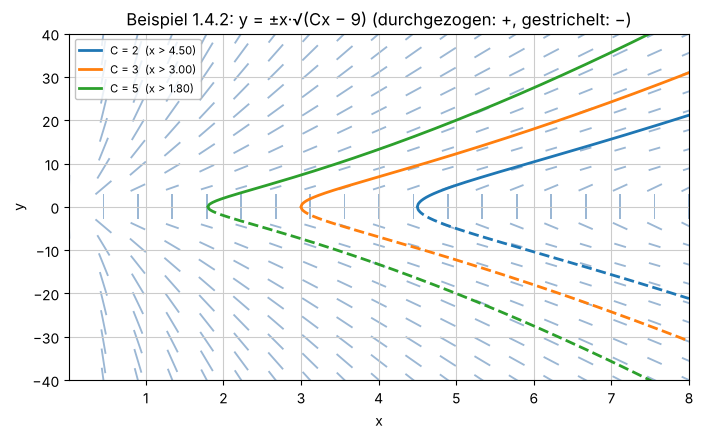

In [22]:
u = sp.Function('u')
f_142 = lambda uu: (9 + 3*uu**2)/(2*uu)
dgl_u = sp.Eq(u(x).diff(x), sp.simplify((f_142(u(x)) - u(x))/x))
display(Markdown('DGL für $u$ nach der Substitution:'), dgl_u)

Cp = sp.symbols('C', positive=True)
xp = sp.symbols('x', positive=True)
for vorzeichen in (+1, -1):
    y_142 = vorzeichen*xp*sp.sqrt(Cp*xp - 9)
    pruefe(f"y = {'+' if vorzeichen > 0 else '-'}x·sqrt(Cx - 9)",
           sp.diff(y_142, xp) - (9*xp**2 + 3*y_142**2)/(2*xp*y_142))

xs_max = 8
for C_wert in (2, 3, 5):
    xs = np.linspace(9/C_wert + 1e-4, xs_max, 400)
    linie, = plt.plot(xs, xs*np.sqrt(C_wert*xs - 9), linewidth=2, label=f'C = {C_wert}  (x > {9/C_wert:.2f})')
    plt.plot(xs, -xs*np.sqrt(C_wert*xs - 9), linewidth=2, color=linie.get_color(), linestyle='--')
richtungsfeld(lambda X, Y: (9*X**2 + 3*Y**2)/(2*X*Y + 1e-12), (0.01, xs_max), (-40, 40), n=19)
plt.xlabel('x'); plt.ylabel('y'); plt.title("Beispiel 1.4.2: y = ±x·√(Cx − 9) (durchgezogen: +, gestrichelt: −)")
plt.legend(fontsize=8); plt.show()

### Beispiel 1.4.3: $y'x - x\cos^2\!\left(\dfrac{y}{x}\right) = y$ für $x > 0$

Division durch $x$: $y' = \dfrac{y}{x} + \cos^2\!\left(\dfrac{y}{x}\right)$. Mit $y = u\,x$, $y' = u'x + u$:
$$u'x + u = u + \cos^2 u \;\Longleftrightarrow\; u' = \frac{\cos^2 u}{x}.$$
Trennung der Variablen:
$$\int\frac{du}{\cos^2 u} = \int\frac{dx}{x} \;\Longrightarrow\; \tan u = \ln x + c \;\Longrightarrow\; u(x) = \arctan(\ln x + c),$$
somit $y(x) = x\cdot\arctan(\ln x + c)$.

(Hinweis für die Probe: $\sin^2 + \cos^2 = 1 \Rightarrow \cos^2(\arctan z) = \dfrac{1}{1 + z^2}$.)

**Merke aus 1.3:** Beim Teilen durch $\cos^2 u$ gehen die Nullstellen $u = \tfrac{\pi}{2} + j\pi$ verloren. Sie liefern die zusätzlichen Lösungen $y = \bigl(\tfrac{\pi}{2} + j\pi\bigr)x$ (Ursprungsgeraden).

In [23]:
y_143 = xp*sp.atan(sp.log(xp) + c_)
pruefe("x y' - x cos²(y/x) - y", xp*sp.diff(y_143, xp) - xp*sp.cos(y_143/xp)**2 - y_143)
y_gerade = (sp.pi/2)*xp
pruefe("Zusatzlösung y = (π/2)·x", xp*sp.diff(y_gerade, xp) - xp*sp.cos(y_gerade/xp)**2 - y_gerade)

Probe x y' - x cos²(y/x) - y: Residuum = 0  -> ok
Probe Zusatzlösung y = (π/2)·x: Residuum = 0  -> ok


**Richtungsfeld:** Die Steigung $f(y/x) = \tfrac{y}{x} + \cos^2\tfrac{y}{x}$ hängt nur von $u = y/x$ ab. Entlang jeder Ursprungsgeraden $y = u\,x$ (gestrichelt, $u = 0{,}5;\ 1;\ 2$) sind alle Striche parallel. Die Lösungskurven $y = x\arctan(\ln x + c)$ schneiden diese Geraden alle unter demselben Winkel.

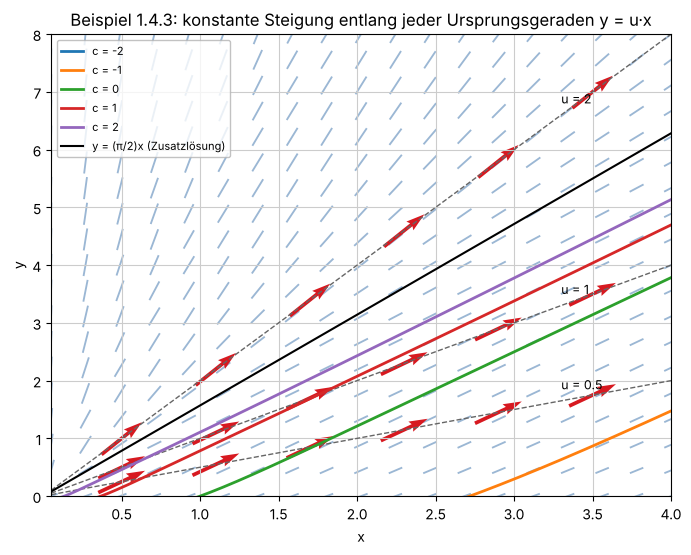

In [24]:
F_143 = lambda X, Y: Y/X + np.cos(Y/X)**2
fig, ax = plt.subplots(figsize=(8, 6))
richtungsfeld(F_143, (0.05, 4), (0, 8), n=19, ax=ax)
xs = np.linspace(0.05, 4, 300)
for u_wert in (0.5, 1, 2):
    ax.plot(xs, u_wert*xs, '--', color='0.4', linewidth=1)
    ax.annotate(f'u = {u_wert:g}', (3.3, u_wert*3.3 + 0.2), fontsize=9)
    # Striche entlang der Geraden hervorheben
    xp_ = np.linspace(0.5, 3.5, 6); yp_ = u_wert*xp_
    m_ = F_143(xp_, yp_); L = np.hypot(1, m_)
    ax.quiver(xp_, yp_, 1/L, m_/L, color='#d71920', pivot='mid', angles='xy', scale=12, width=0.006)
xs = np.linspace(0.02, 4, 400)
for c_wert in (-2, -1, 0, 1, 2):
    ax.plot(xs, xs*np.arctan(np.log(xs) + c_wert), linewidth=2, label=f'c = {c_wert}')
ax.plot(xs, np.pi/2*xs, color='black', linewidth=1.5, label='y = (π/2)x (Zusatzlösung)')
ax.set(xlabel='x', ylabel='y', title="Beispiel 1.4.3: konstante Steigung entlang jeder Ursprungsgeraden y = u·x")
ax.legend(loc='upper left', fontsize=8); plt.show()

### Lösungsmethode 1.4.4 (Ähnlichkeitsdifferentialgleichung)

Die Lösung von $y' = f(y/x)$, $y(x_0) = y_0$ erhält man mit der neuen Variablen $u = \dfrac{y}{x}$:

1. Aus $y(x) = u(x)\cdot x$ folgt durch Ableitung $y'(x) = u'(x)\cdot x + u(x)$.
2. Einsetzen in $y' = f(y/x)$ ergibt $u'(x)\cdot x + u(x) = f(u)$ mit der Anfangsbedingung $u(x_0) = \dfrac{y_0}{x_0}$.
3. Auflösen nach $u'$ ergibt $u' = \dfrac{f(u) - u}{x}$.
4. Lösung dieser Anfangswertaufgabe nach der Methode der getrennten Variablen ergibt $u(x)$.
5. Rücksubstitution: $y(x) = u(x)\cdot x$.

**Übliche Substitutionen:**

| Typ | DGL | Substitution |
|---|---|---|
| A | $y' = f\!\left(\dfrac{y}{x}\right)$ (Ähnlichkeits-DGL) | $u = \dfrac{y}{x}$ |
| B | $y' + g(x)\,y = h(x)\,y^n$ (Bernoullische DGL, hier nicht behandelt) | $u = y^{1-n}$ |

Die Hilfsfunktion unten führt die Schritte 1 bis 3 automatisch aus und übergibt die entstehende trennbare DGL an `dsolve`.

Schritt 3, trennbare DGL für $u$:

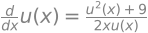

Schritt 5, Rücksubstitution $y = u\cdot x$:

In [25]:
def aehnlichkeits_dgl(f):
    """Löst y' = f(y/x) nach Lösungsmethode 1.4.4 und gibt y(x) zurück (allgemeine Lösung)."""
    u = sp.Function('u')
    schritt3 = sp.Eq(u(x).diff(x), sp.simplify((f(u(x)) - u(x))/x))
    display(Markdown('Schritt 3, trennbare DGL für $u$:'), schritt3)
    loes_u = sp.dsolve(schritt3)
    loes_u = loes_u if isinstance(loes_u, list) else [loes_u]
    ergebnisse = [sp.simplify(l.rhs*x) for l in loes_u]
    display(Markdown('Schritt 5, Rücksubstitution $y = u\\cdot x$:'), *ergebnisse)
    return ergebnisse

_ = aehnlichkeits_dgl(lambda uu: (9 + 3*uu**2)/(2*uu))    # Beispiel 1.4.2

### Beispiele 1.4.5 und 1.4.6 (Übung)

Bestimmen Sie die Lösung mit der Substitution $u = y/x$ für $x > 0$:

* **Beispiel 1.4.5:** $y' = \dfrac{x + y}{x}$
* **Beispiel 1.4.6:** $y' = \dfrac{y}{x} + \left(\dfrac{y}{x}\right)^2$

Rechnen Sie zuerst von Hand. Die Musterlösung lässt sich aufklappen, die Codezelle danach prüft die Ergebnisse.

<details>
<summary><b>Musterlösung Beispiel 1.4.5</b> (zum Aufklappen anklicken)</summary>

$f(u) = 1 + u$. Mit $y = ux$: $u'x + u = 1 + u \;\Rightarrow\; u' = \dfrac{1}{x} \;\Rightarrow\; u = \ln x + C$.
Rücksubstitution: $\boxed{y = x(\ln x + C)}$.
</details>

<details>
<summary><b>Musterlösung Beispiel 1.4.6</b> (zum Aufklappen anklicken)</summary>

$f(u) = u + u^2$. Mit $y = ux$: $u'x + u = u + u^2 \;\Rightarrow\; u' = \dfrac{u^2}{x}$.
Für $u \ne 0$: $\displaystyle\int\frac{du}{u^2} = \int\frac{dx}{x} \;\Rightarrow\; -\frac{1}{u} = \ln x + C \;\Rightarrow\; u = -\frac{1}{\ln x + C}$.
Rücksubstitution: $\boxed{y = -\dfrac{x}{\ln x + C}}$ (für $\ln x + C \ne 0$).
Zusätzlich: $u \equiv 0$, also $y \equiv 0$ (Nullstelle von $u^2$, beim Teilen verloren).
</details>

Probe Bsp. 1.4.5: y' - (x + y)/x: Residuum = 0  -> ok
Probe Bsp. 1.4.6: y' - y/x - (y/x)²: Residuum = 0  -> ok
Probe Bsp. 1.4.6: y ≡ 0: Residuum = 0  -> ok


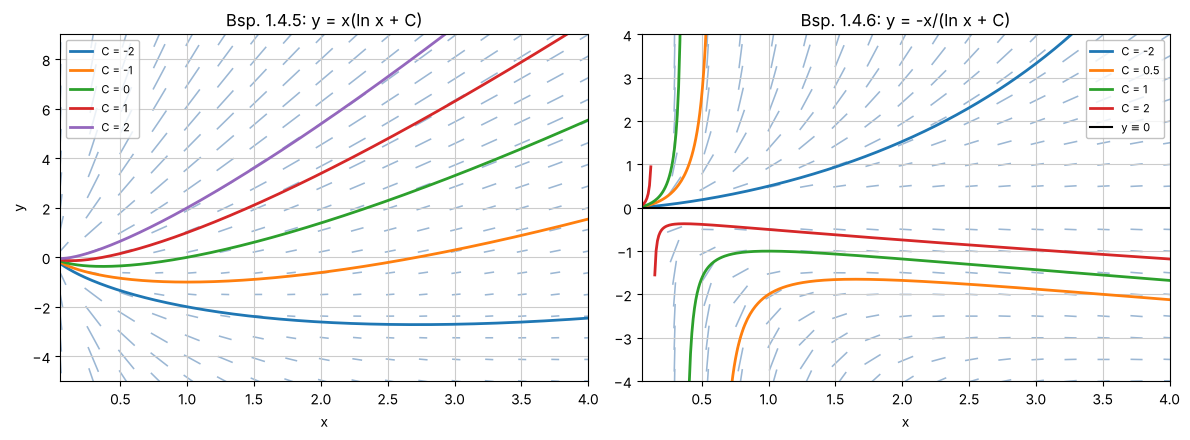

In [26]:
C = sp.symbols('C', real=True)
y_145 = xp*(sp.log(xp) + C)
pruefe("Bsp. 1.4.5: y' - (x + y)/x", sp.diff(y_145, xp) - (xp + y_145)/xp)
y_146 = -xp/(sp.log(xp) + C)
pruefe("Bsp. 1.4.6: y' - y/x - (y/x)²", sp.diff(y_146, xp) - y_146/xp - (y_146/xp)**2)
pruefe("Bsp. 1.4.6: y ≡ 0", sp.Integer(0))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
richtungsfeld(lambda X, Y: (X + Y)/X, (0.05, 4), (-5, 9), n=17, ax=ax1)
xs = np.linspace(0.05, 4, 400)
for C_wert in (-2, -1, 0, 1, 2):
    ax1.plot(xs, xs*(np.log(xs) + C_wert), linewidth=2, label=f'C = {C_wert}')
ax1.set(title="Bsp. 1.4.5: y = x(ln x + C)", xlabel='x', ylabel='y'); ax1.legend(fontsize=8)

richtungsfeld(lambda X, Y: Y/X + (Y/X)**2, (0.05, 4), (-4, 4), n=17, ax=ax2)
for C_wert in (-2, 0.5, 1, 2):
    y_werte = -xs/(np.log(xs) + C_wert)
    y_werte[np.abs(np.log(xs) + C_wert) < 0.05] = np.nan    # Polstelle ln x = -C ausblenden
    ax2.plot(xs, y_werte, linewidth=2, label=f'C = {C_wert}')
ax2.axhline(0, color='black', linewidth=1.5, label='y ≡ 0')
ax2.set(title="Bsp. 1.4.6: y = -x/(ln x + C)", xlabel='x', ylim=(-4, 4)); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Lösungsschema für Ähnlichkeits-DGL $y' = f(y/x)$ (Zusammenfassung)

Die Substitution $u = y/x$ macht aus der Ähnlichkeits-DGL eine trennbare DGL in $u$ und $x$:

1. Substitution ansetzen: $u(x) = y(x)/x$, also $y(x) = u(x)\cdot x$
2. Ableiten (Produktregel): $y'(x) = u'(x)\cdot x + u(x)$
3. Einsetzen in $y' = f(y/x)$: $u'x + u = f(u) \;\Rightarrow\; u' = \dfrac{f(u) - u}{x}$
4. Variablen trennen: $\dfrac{du}{f(u) - u} = \dfrac{dx}{x}$
5. Beide Seiten integrieren und nach $u(x)$ auflösen
6. Rücksubstitution: $y(x) = u(x)\cdot x$

**Woran erkennt man diesen Typ?**

* Die rechte Seite lässt sich als Funktion des Quotienten $y/x$ schreiben, z. B. $y' = \dfrac{9 + 3(y/x)^2}{2\,y/x}$ oder $y'x - x\cos^2(y/x) = y$.
* Auf jeder Ursprungsgeraden $y = u\,x$ ist $y/x$ konstant, daher hängt die Steigung nur von $u$ ab (Abbildung zu Beispiel 1.4.3).
* Nach der Rücksubstitution immer die Bedingung $x > 0$ bzw. $x \ne 0$ prüfen.

Schritt 4 ist genau die Trennung der Variablen aus Abschnitt 1.3; die Substitution führt den neuen Typ also auf ein bekanntes Verfahren zurück.

## 5. Ausblick: Numerische Lösung mit dem Euler-Verfahren (Kapitel 4)

Nicht jede DGL lässt sich geschlossen lösen. Das **explizite Euler-Verfahren** folgt dem Richtungsfeld in kleinen geraden Schritten: Aus dem bekannten Wert $y_n$ wird mit der dortigen Steigung der nächste Wert berechnet,
$$y_{n+1} = y_n + h\cdot F(x_n, y_n).$$
Die globale Fehlerordnung ist $O(h)$: Halbiert man die Schrittweite, halbiert sich ungefähr auch der Fehler. Ausführlich wird das in Kapitel 4 (Numerik) behandelt. Hier vergleichen wir es mit der exakten Lösung des Kaffee-Beispiels 1.3.6.

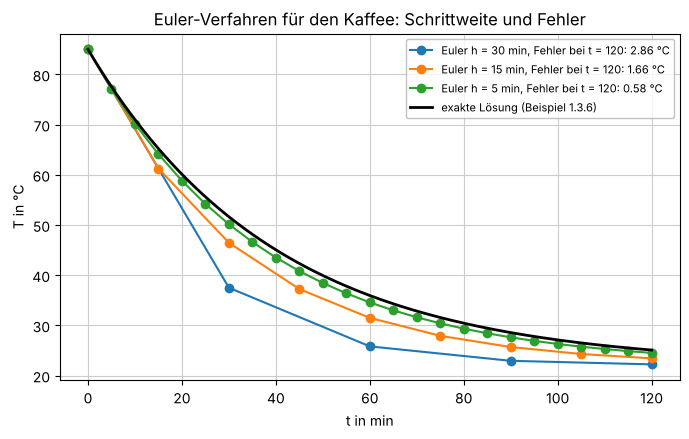

In [27]:
def euler(F, x0, y0, h, schritte):
    xs = [x0]; ys = [float(y0)]
    for _ in range(schritte):
        ys.append(ys[-1] + h*F(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return np.array(xs), np.array(ys)

k_num = float(k_wert)
F_kaffee = lambda tt, TT: -k_num*(TT - 22)
ts = np.linspace(0, 120, 400)
for h in (30.0, 15.0, 5.0):
    te, Te = euler(F_kaffee, 0, 85, h, int(120/h))
    fehler = abs(Te[-1] - f_T(120))
    plt.plot(te, Te, 'o-', label=f'Euler h = {h:g} min, Fehler bei t = 120: {fehler:.2f} °C')
plt.plot(ts, f_T(ts), color='black', linewidth=2, label='exakte Lösung (Beispiel 1.3.6)')
plt.xlabel('t in min'); plt.ylabel('T in °C'); plt.title('Euler-Verfahren für den Kaffee: Schrittweite und Fehler')
plt.legend(fontsize=8); plt.show()